# Calcul de la phase lunaire (Soleil-Terre-Lune)

Ce notebook implémente les équations de la section d'application du document LaTeX (`phase_de_lune.pdf`), en particulier les équations **(64) à (97)**.

Objectif : obtenir une évaluation robuste et précise de la phase lunaire topocentrique $\mathcal{P}(t)$, sans simplification géométrique de l'intersection des calottes.

- Dynamique : système newtonien couplé Terre/Lune dans le repère héliocentrique (eq. 66-68).
- Géométrie : vecteurs de visée et d'éclairement (eq. 72-78).
- Phase : définition intégrale exacte sur le domaine $\mathcal{D}(t)$ (eq. 87-91).

In [21]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Callable, Optional

import numpy as np
from scipy.integrate import solve_ivp, quad
import matplotlib.pyplot as plt

In [22]:
# Constantes physiques et paramètres du modèle
@dataclass(frozen=True)
class PhysicalConstants:
    """Constantes SI utilisées dans le modèle."""

    G: float = 6.67430e-11
    m_s: float = 1.98847e30
    m_t: float = 5.9722e24
    m_l: float = 7.342e22

    R_s: float = 6.9634e8
    R_t: float = 6.371e6
    R_l: float = 1.7374e6
    R_j: float = 6.9911e7  # rayon équatorial moyen de Jupiter (m)

    earth_obliquity_rad: float = np.deg2rad(23.439281)
    earth_sidereal_omega: float = 7.2921150e-5  # rad/s
    jupiter_obliquity_rad: float = np.deg2rad(3.13)
    jupiter_sidereal_omega: float = 2.0 * np.pi / (9.925 * 3600.0)  # rad/s


@dataclass(frozen=True)
class OrbitalElements:
    """Éléments képlériens osculateurs moyens à l'époque de référence."""

    a_m: float
    e: float
    i_rad: float
    raan_rad: float
    argp_rad: float
    M0_rad: float
    period_s: float


@dataclass(frozen=True)
class InitialState:
    """Données initiales du flot newtonien (eq. 68, 94)."""

    r_t0: np.ndarray  # SC_T(0), shape (3,)
    v_t0: np.ndarray  # d/dt SC_T(0), shape (3,)
    r_l0: np.ndarray  # SC_L(0), shape (3,)
    v_l0: np.ndarray  # d/dt SC_L(0), shape (3,)


@dataclass(frozen=True)
class Observer:
    """Observateur de surface (latitude/longitude en radians, altitude nulle)."""

    latitude_rad: float
    longitude_rad: float


CONST = PhysicalConstants()

# Paramètres orbitaux de référence (J2000 approchés, usage de simulation)
EARTH_ORBIT = OrbitalElements(
    a_m=149_597_870_700.0,
    e=0.0167086,
    i_rad=np.deg2rad(0.00005),
    raan_rad=np.deg2rad(-11.26064),
    argp_rad=np.deg2rad(114.20783),
    M0_rad=np.deg2rad(357.51716),
    period_s=365.256363004 * 86400.0,
)

MOON_ORBIT_GEO = OrbitalElements(
    a_m=384_400_000.0,
    e=0.0549,
    i_rad=np.deg2rad(5.145),
    raan_rad=np.deg2rad(125.08),
    argp_rad=np.deg2rad(318.15),
    M0_rad=np.deg2rad(115.3654),
    period_s=27.321661 * 86400.0,
)

PARIS_CENTER = Observer(
    latitude_rad=np.deg2rad(48.8566),
    longitude_rad=np.deg2rad(2.3522),
)

# Point d'observation sur la surface de Jupiter
JUPITER_SITE = Observer(
    latitude_rad=np.deg2rad(45),
    longitude_rad=np.deg2rad(0.0),
)

In [23]:
# Outils géométriques : rotations (eq. 70), normalisation, garde numérique
def r1(angle: float) -> np.ndarray:
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[1.0, 0.0, 0.0], [0.0, c, -s], [0.0, s, c]], dtype=float)


def r3(angle: float) -> np.ndarray:
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]], dtype=float)


def unit(v: np.ndarray, eps: float = 1e-15) -> np.ndarray:
    n = np.linalg.norm(v)
    if n <= eps:
        raise ValueError("Norme trop faible pour normalisation.")
    return v / n


def clamp(x: float, lo: float, hi: float) -> float:
    return max(lo, min(hi, x))


def rotating_body_matrix(theta_t: float, obliquity: float) -> np.ndarray:
    """Matrice d'orientation inertielle d'un corps en rotation: R3(theta) R1(obliquité)."""
    return r3(theta_t) @ r1(obliquity)


def earth_rotation_matrix(theta_t: float, obliquity: float = CONST.earth_obliquity_rad) -> np.ndarray:
    """Q_T(t) = R3(Theta_T(t)) R1(epsilon_T) (eq. 70)."""
    return rotating_body_matrix(theta_t, obliquity)


def sidereal_angle_linear(t: float, theta0: float = 0.0, omega: float = CONST.earth_sidereal_omega) -> float:
    """Modèle sidéral simple : Theta_T(t) = theta0 + omega t."""
    return theta0 + omega * t


def observer_position_on_rotating_body(
    t: float,
    r_center: np.ndarray,
    obs: Observer,
    radius: float,
    theta_fn: Callable[[float], float],
    obliquity: float = 0.0,
) -> np.ndarray:
    """Position inertielle d'un observateur à la surface d'un corps en rotation."""
    phi = obs.latitude_rad
    lam = obs.longitude_rad

    local = np.array([
        np.cos(phi) * np.cos(lam),
        np.cos(phi) * np.sin(lam),
        np.sin(phi),
    ])
    q = rotating_body_matrix(theta_fn(t), obliquity)
    return r_center + q @ (radius * local)


def is_target_above_local_horizon(r_center: np.ndarray, p_obs: np.ndarray, r_target: np.ndarray) -> bool:
    """Vrai si la cible est au-dessus de l'horizon local (normale sortante au point observateur)."""
    n_local = p_obs - r_center
    los = r_target - p_obs
    return float(np.dot(n_local, los)) >= 0.0

In [24]:
# Dynamique Soleil-Terre-Lune (eq. 65 à 68)
def rhs_three_body_sun_earth_moon(t: float, y: np.ndarray, c: PhysicalConstants = CONST) -> np.ndarray:
    """
    y = [r_T, v_T, r_L, v_L] en repère héliocentrique.
    Soleil fixé à l'origine (eq. 64), Terre/Lune couplées (eq. 66-67).
    """
    r_t = y[0:3]
    v_t = y[3:6]
    r_l = y[6:9]
    v_l = y[9:12]

    r_t_norm = np.linalg.norm(r_t)
    r_l_norm = np.linalg.norm(r_l)
    r_lt = r_l - r_t
    r_tl = r_t - r_l
    r_lt_norm = np.linalg.norm(r_lt)

    a_t = -c.G * c.m_s * r_t / (r_t_norm**3) + c.G * c.m_l * r_lt / (r_lt_norm**3)
    a_l = -c.G * c.m_s * r_l / (r_l_norm**3) + c.G * c.m_t * r_tl / (r_lt_norm**3)

    return np.concatenate((v_t, a_t, v_l, a_l))


def propagate_state(
    init: InitialState,
    t_span: tuple[float, float],
    t_eval: np.ndarray,
    rtol: float = 1e-12,
    atol: float = 1e-15,
    method: str = "DOP853",
):
    """Propagation haute précision du flot newtonien."""
    y0 = np.concatenate((init.r_t0, init.v_t0, init.r_l0, init.v_l0)).astype(float)

    sol = solve_ivp(
        fun=rhs_three_body_sun_earth_moon,
        t_span=t_span,
        y0=y0,
        t_eval=t_eval,
        method=method,
        rtol=rtol,
        atol=atol,
        dense_output=False,
    )

    if not sol.success:
        raise RuntimeError(f"Échec solveur ODE: {sol.message}")

    return sol

In [25]:
# Phase lunaire topocentrique : implémentation robuste des eq. 71 à 93 + éphemerides képlériennes Terre/Lune
def observer_position_sp_t(
    t: float,
    r_t: np.ndarray,
    obs: Observer,
    theta_fn: Callable[[float], float],
    c: PhysicalConstants = CONST,
) -> np.ndarray:
    """Position SP_T(t) (eq. 71 et 96), altitude nulle."""
    phi = obs.latitude_rad
    lam = obs.longitude_rad

    local = np.array([
        np.cos(phi) * np.cos(lam),
        np.cos(phi) * np.sin(lam),
        np.sin(phi),
    ])

    q_t = earth_rotation_matrix(theta_fn(t))
    return r_t + q_t @ (c.R_t * local)


def visibility_condition_v_tl_1(r_t: np.ndarray, r_l: np.ndarray, p_t: np.ndarray) -> bool:
    """V_TL^(1): C_TP_T · P_TC_L >= 0 (eq. 82)."""
    ct_pt = p_t - r_t
    pt_cl = r_l - p_t
    return float(np.dot(ct_pt, pt_cl)) >= 0.0


def phase_angle_chi(r_l: np.ndarray, p_t: np.ndarray) -> float:
    """Angle chi(t) (eq. 75 et forme explicite eq. 93)."""
    u_sl = unit(-r_l)
    u_pl = unit(p_t - r_l)
    return float(np.arccos(clamp(float(np.dot(u_sl, u_pl)), -1.0, 1.0)))


def _phi_measure_geq_cos(threshold: float) -> float:
    """Mesure de {phi in [-pi, pi] | cos(phi) >= threshold}."""
    if threshold <= -1.0:
        return 2.0 * np.pi
    if threshold >= 1.0:
        return 0.0
    return 2.0 * np.arccos(threshold)


def _intersection_fraction_caps(
    s_obs: float,
    s_sun: float,
    chi: float,
    epsabs: float = 1e-8,
    epsrel: float = 1e-8,
) -> float:
    """
    Fraction d'aire de la zone visible éclairée rapportée à la zone visible.

    Convention locale (sphère unitaire centrée sur la Lune):
    - visibilité observateur : n·u_obs >= s_obs, avec s_obs = R_L / d_PL
    - illumination solaire   : n·u_sun >= -s_sun, avec s_sun = (R_S - R_L) / D_SL

    Cette convention corrige un décalage d'orientation entre les notations du cône type 1
    et le repère local (u_obs dirigé Lune -> observateur).
    """
    # Domaine visibilité non vide
    if s_obs >= 1.0:
        return 0.0
    if s_obs <= -1.0:
        denom = 4.0 * np.pi
    else:
        denom = 2.0 * np.pi * (1.0 - s_obs)

    if denom <= 0.0:
        return 0.0

    sin_chi = np.sin(chi)
    cos_chi = np.cos(chi)

    # x = n·u_obs = cos(psi), domaine visible : x in [s_obs, 1]
    x_min, x_max = max(-1.0, s_obs), 1.0

    def phi_measure_for_x(x: float) -> float:
        sin_psi = np.sqrt(max(0.0, 1.0 - x * x))
        a = sin_psi * sin_chi
        b = x * cos_chi

        # Inégalité illumination: b + a cos(phi) >= -s_sun
        if abs(a) < 1e-16:
            return 2.0 * np.pi if b >= -s_sun else 0.0

        threshold = (-s_sun - b) / a  # cos(phi) >= threshold
        return _phi_measure_geq_cos(threshold)

    numer, _ = quad(phi_measure_for_x, x_min, x_max, epsabs=epsabs, epsrel=epsrel, limit=300)
    return float(clamp(numer / denom, 0.0, 1.0))


def phase_fraction_exact(
    t: float,
    r_t: np.ndarray,
    r_l: np.ndarray,
    obs: Observer,
    theta_fn: Callable[[float], float],
    c: PhysicalConstants = CONST,
    require_visibility: bool = False,
) -> float:
    """
    Évalue P(t) selon la définition intégrale (eq. 90-91).
    Si require_visibility=True, retourne NaN quand V_TL^(1) est fausse.
    """
    p_t = observer_position_sp_t(t, r_t, obs, theta_fn, c)

    visible_local = visibility_condition_v_tl_1(r_t, r_l, p_t)
    if require_visibility and not visible_local:
        return np.nan

    d_sl = float(np.linalg.norm(r_l))
    d_pl = float(np.linalg.norm(p_t - r_l))
    if d_sl <= 0.0 or d_pl <= 0.0:
        return np.nan

    if abs(c.R_s - c.R_l) > d_sl or c.R_l > d_pl:
        return np.nan

    s_sun = (c.R_s - c.R_l) / d_sl
    s_obs = c.R_l / d_pl
    chi = phase_angle_chi(r_l, p_t)
    return _intersection_fraction_caps(s_obs=s_obs, s_sun=s_sun, chi=chi)


def phase_fraction_photometric(
    t: float,
    r_t: np.ndarray,
    r_l: np.ndarray,
    obs: Observer,
    theta_fn: Callable[[float], float],
    c: PhysicalConstants = CONST,
    require_visibility: bool = False,
) -> float:
    """
    Fraction photométrique lisse : (1 + cos(chi)) / 2.
    Très stable pour la visualisation des phases standard.
    """
    p_t = observer_position_sp_t(t, r_t, obs, theta_fn, c)
    if require_visibility and (not visibility_condition_v_tl_1(r_t, r_l, p_t)):
        return np.nan
    chi = phase_angle_chi(r_l, p_t)
    return float(0.5 * (1.0 + np.cos(chi)))

def _rot_313(raan: float, inc: float, argp: float) -> np.ndarray:
    return r3(raan) @ r1(inc) @ r3(argp)


def solve_kepler_elliptic(M: float, e: float, tol: float = 1e-10, max_iter: int = 20) -> float:
    """Résout M = E - e sin(E) (orbite elliptique)."""
    M_wrapped = (M + np.pi) % (2.0 * np.pi) - np.pi
    E = M_wrapped if e < 0.8 else np.pi
    for _ in range(max_iter):
        f = E - e * np.sin(E) - M_wrapped
        fp = 1.0 - e * np.cos(E)
        dE = -f / fp
        E = E + dE
        if abs(dE) < tol:
            break
    return E


def kepler_state_from_elements(el: OrbitalElements, t: float) -> tuple[np.ndarray, np.ndarray]:
    """État cartésien inertiel à l'instant t à partir d'éléments képlériens."""
    n = 2.0 * np.pi / el.period_s
    M = el.M0_rad + n * t
    E = solve_kepler_elliptic(M, el.e)

    ce, se = np.cos(E), np.sin(E)
    fac = np.sqrt(1.0 - el.e * el.e)

    r_pf = np.array([el.a_m * (ce - el.e), el.a_m * fac * se, 0.0])
    v_pf = np.array([
        -el.a_m * n * se / (1.0 - el.e * ce),
        el.a_m * n * fac * ce / (1.0 - el.e * ce),
        0.0,
    ])

    q = _rot_313(el.raan_rad, el.i_rad, el.argp_rad)
    r = q @ r_pf
    v = q @ v_pf
    return r, v

In [26]:
# Ephémérides képlériennes + phase
def compute_ephemerides_kepler(
    t_eval: np.ndarray,
    earth_orbit: OrbitalElements = EARTH_ORBIT,
    moon_orbit_geo: OrbitalElements = MOON_ORBIT_GEO,
    c: PhysicalConstants = CONST,
) -> dict[str, np.ndarray]:
    """
    Génère r_T, v_T, r_L, v_L dans le repère héliocentrique.
    - Terre : képlerien autour du Soleil
    - Lune : képlerien autour de la Terre, puis composition héliocentrique
    """
    _ = c  # conservé pour homogénéité d'API
    r_t = np.empty((t_eval.size, 3), dtype=float)
    v_t = np.empty((t_eval.size, 3), dtype=float)
    r_l = np.empty((t_eval.size, 3), dtype=float)
    v_l = np.empty((t_eval.size, 3), dtype=float)

    for i, t in enumerate(t_eval):
        rE, vE = kepler_state_from_elements(earth_orbit, float(t))
        rM_geo, vM_geo = kepler_state_from_elements(moon_orbit_geo, float(t))

        r_t[i] = rE
        v_t[i] = vE
        r_l[i] = rE + rM_geo
        v_l[i] = vE + vM_geo

    return {"r_t": r_t, "v_t": v_t, "r_l": r_l, "v_l": v_l}


def compute_phase_timeseries(
    obs: Observer,
    t_eval: np.ndarray,
    theta_fn: Optional[Callable[[float], float]] = None,
    c: PhysicalConstants = CONST,
    earth_orbit: OrbitalElements = EARTH_ORBIT,
    moon_orbit_geo: OrbitalElements = MOON_ORBIT_GEO,
    require_visibility_for_exact: bool = True,
) -> dict[str, np.ndarray]:
    if theta_fn is None:
        theta_fn = sidereal_angle_linear

    eph = compute_ephemerides_kepler(t_eval=t_eval, earth_orbit=earth_orbit, moon_orbit_geo=moon_orbit_geo, c=c)
    r_t = eph["r_t"]
    r_l = eph["r_l"]

    phase_exact = np.empty_like(t_eval, dtype=float)
    phase_photo = np.empty_like(t_eval, dtype=float)
    visible = np.empty_like(t_eval, dtype=bool)

    for i, t in enumerate(t_eval):
        p_t = observer_position_sp_t(float(t), r_t[i], obs, theta_fn, c)
        visible[i] = visibility_condition_v_tl_1(r_t[i], r_l[i], p_t)

        phase_exact[i] = phase_fraction_exact(
            t=float(t),
            r_t=r_t[i],
            r_l=r_l[i],
            obs=obs,
            theta_fn=theta_fn,
            c=c,
            require_visibility=require_visibility_for_exact,
        )
        phase_photo[i] = phase_fraction_photometric(
            t=float(t),
            r_t=r_t[i],
            r_l=r_l[i],
            obs=obs,
            theta_fn=theta_fn,
            c=c,
        )

    phase_exact_visible = np.where(visible, phase_exact, np.nan)
    phase_photo_visible = np.where(visible, phase_photo, np.nan)

    return {
        "t": t_eval,
        "phase": phase_exact,
        "phase_photometric": phase_photo,
        "phase_visible": phase_exact_visible,
        "phase_photometric_visible": phase_photo_visible,
        "visible": visible,
        "r_t": r_t,
        "r_l": r_l,
    }

In [27]:
# Paramètres d'exécution : observateur et fenêtre temporelle
observer = PARIS_CENTER  # centre de Paris

# Horizon temporel: 112 jours (4 cycles lunaires)
t_eval = np.arange(0.0, 112.0 * 24.0 * 3600.0 + 3600.0, 3600.0)

result = compute_phase_timeseries(
    obs=observer,
    t_eval=t_eval,
    theta_fn=sidereal_angle_linear,
    require_visibility_for_exact=True, # True => trous quand la Lune est sous l'horizon
    earth_orbit=EARTH_ORBIT,
    moon_orbit_geo=MOON_ORBIT_GEO,
    c=CONST,
)

# Aperçu de 1 valeur sur 14
result["phase_photometric_visible"][::14]

KeyboardInterrupt: 

## Lecture du résultat
- Phase topocentrique par intersection exacte des calottes (équations du document).
- Fraction photométrique $\frac{1+\cos\chi}{2}$, plus lisse pour lecture des phases classiques.

Le modèle utilise un observateur fixé au centre de Paris et des éléments orbitaux képlériens de référence Terre/Lune.

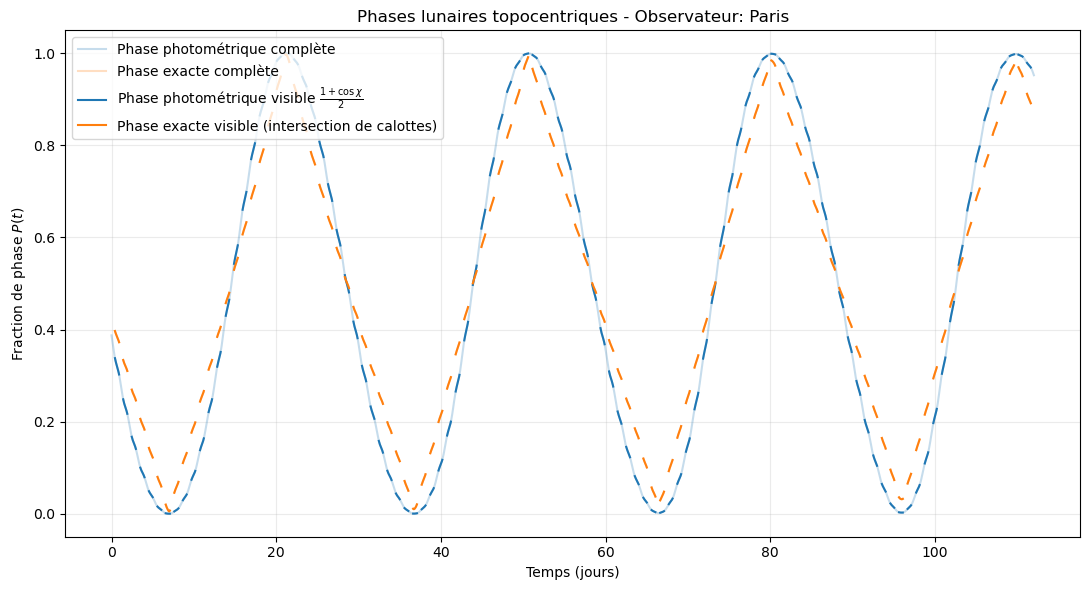

In [ ]:
# Graphique des phases lunaires
t_days = result["t"] / 86400.0
phase_exact = result["phase_visible"]
phase_photo = result["phase_photometric_visible"]
phase_exact_full = result["phase"]
phase_photo_full = result["phase_photometric"]

fig, ax = plt.subplots(figsize=(11, 6))

# Versions complètes (sans masque visibilité) en arrière-plan
ax.plot(
    t_days,
    phase_photo_full,
    color="#1f77b4",
    alpha=0.25,
    label="Phase photométrique complète",
)
ax.plot(
    t_days,
    phase_exact_full,
    color="#ff7f0e",
    alpha=0.25,
    label="Phase exacte complète",
)

# Versions visibles (avec trous)
ax.plot(
    t_days,
    phase_photo,
    color="#1f77b4",
    label="Phase photométrique visible $\\frac{1+\\cos\\chi}{2}$",
)
ax.plot(
    t_days,
    phase_exact,
    color="#ff7f0e",
    label="Phase exacte visible (intersection de calottes)",
)

ax.set_xlabel("Temps (jours)")
ax.set_ylabel("Fraction de phase $P(t)$")
ax.set_title("Phases lunaires topocentriques - Observateur: Paris")
ax.grid(True, alpha=0.25)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

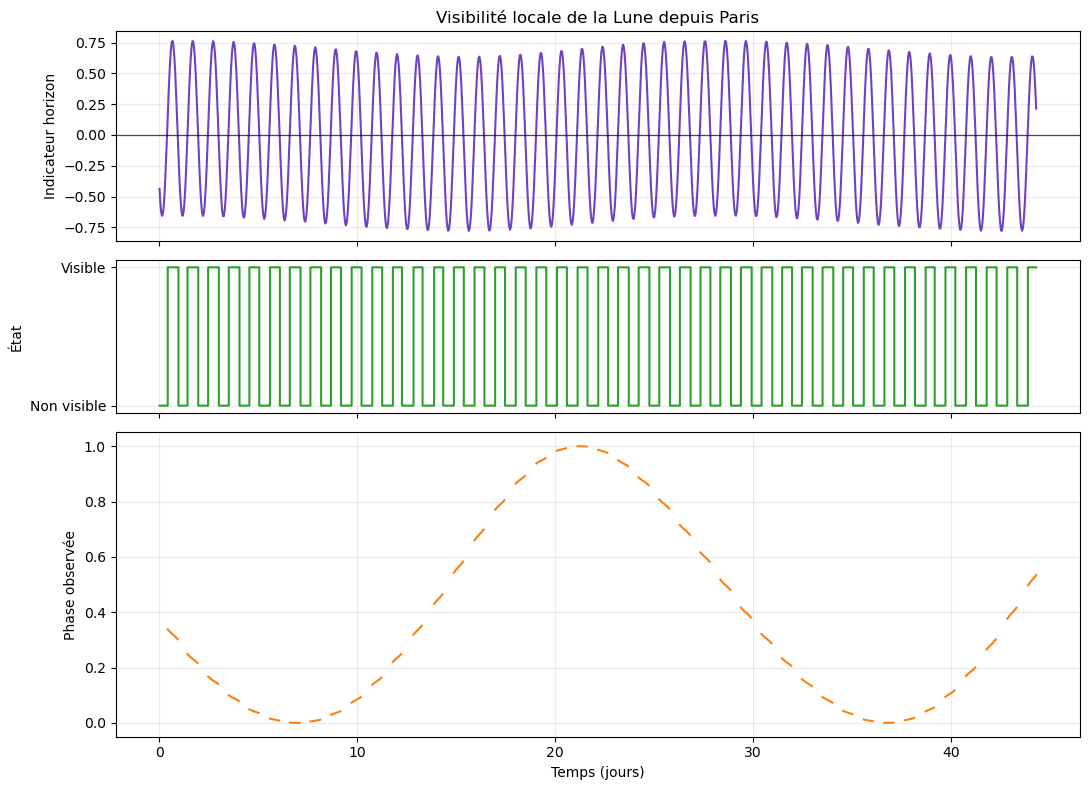

In [ ]:
# Graphiques supplémentaires: ce que voit réellement l'observateur (Paris)
t_days = result["t"] / 86400.0
visible = result["visible"]
phase_obs = result["phase_photometric_visible"]

# On affiche 1,5 cycle synodique lunaire
synodic_days = 29.530588
window_days = 1.5 * synodic_days
window_mask = t_days <= (t_days[0] + window_days)

t_plot = t_days[window_mask]
visible_plot = visible[window_mask]
phase_obs_plot = phase_obs[window_mask]

# Indicateur signé d'horizon: >0 visible, <0 sous l'horizon
horizon_signed = np.empty_like(t_plot, dtype=float)
for i, t in enumerate(result["t"][window_mask]):
    r_t_i = result["r_t"][window_mask][i]
    r_l_i = result["r_l"][window_mask][i]
    p_t_i = observer_position_sp_t(float(t), r_t_i, observer, sidereal_angle_linear, CONST)
    ct_pt = p_t_i - r_t_i
    pt_cl = r_l_i - p_t_i
    denom = np.linalg.norm(ct_pt) * np.linalg.norm(pt_cl)
    horizon_signed[i] = np.dot(ct_pt, pt_cl) / denom if denom > 0 else np.nan

visible_step = visible_plot.astype(float)

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [1.1, 0.8, 1.6]})

# Hauteur signée relative à l'horizon local
axes[0].plot(t_plot, horizon_signed, color="#6f42c1")
axes[0].axhline(0.0, color="black", lw=0.9, alpha=0.7)
axes[0].set_ylabel("Indicateur horizon")
axes[0].set_title("Visibilité locale de la Lune depuis Paris")
axes[0].grid(True, alpha=0.25)

# Signal binaire visible / non visible
axes[1].step(t_plot, visible_step, where="post", color="#2ca02c")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Non visible", "Visible"])

axes[1].set_ylabel("État")
axes[1].grid(True, alpha=0.25)

# Phase réellement observable (trous automatiques)
axes[2].plot(t_plot, phase_obs_plot, color="#ff7f0e")
axes[2].set_ylabel("Phase observée")
axes[2].set_xlabel("Temps (jours)")
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Contrôles qualité (diagnostic)
phase_exact = result["phase"]
phase_photo = result["phase_photometric"]
phase_exact_visible = result["phase_visible"]
phase_photo_visible = result["phase_photometric_visible"]
visible = result["visible"]

valid_exact = np.isfinite(phase_exact)
valid_photo = np.isfinite(phase_photo)
valid_exact_visible = np.isfinite(phase_exact_visible)
valid_photo_visible = np.isfinite(phase_photo_visible)

print("--- Visibilité locale (Paris) ---")
print(f"Points visibles: {int(visible.sum())} / {visible.size} ({visible.mean():.1%})")
print("\n--- Qualité phase exacte (sans masque) ---")
print(f"Points valides: {int(valid_exact.sum())} / {phase_exact.size}")
if valid_exact.any():
    print(f"Min/Max: {np.nanmin(phase_exact):.6f} / {np.nanmax(phase_exact):.6f}")

print("\n--- Qualité phase photométrique (sans masque) ---")
print(f"Points valides: {int(valid_photo.sum())} / {phase_photo.size}")
if valid_photo.any():
    print(f"Min/Max: {np.nanmin(phase_photo):.6f} / {np.nanmax(phase_photo):.6f}")

print("\n--- Courbes affichées (avec masque visibilité) ---")
print(f"Exact visible: {int(valid_exact_visible.sum())} / {phase_exact_visible.size}")
print(f"Photo visible: {int(valid_photo_visible.sum())} / {phase_photo_visible.size}")

--- Visibilité locale (Paris) ---
Points visibles: 1327 / 2689 (49.3%)

--- Qualité phase exacte (sans masque) ---
Points valides: 1327 / 2689
Min/Max: 0.005124 / 0.998109

--- Qualité phase photométrique (sans masque) ---
Points valides: 2689 / 2689
Min/Max: 0.000059 / 0.999917

--- Courbes affichées (avec masque visibilité) ---
Exact visible: 1327 / 2689
Photo visible: 1327 / 2689


## Variante complexe : système Soleil–Jupiter–Lune terrestre
Même logique d'affichage que ci-dessus, avec vérification supplémentaire d'occultation :
- Jupiter ne doit pas voir la Lune à travers le Soleil ;
- Jupiter ne doit pas voir la Lune à travers la Terre.

In [ ]:
# Paramètres et fonctions Jupiter -> Lune terrestre (observateur à la surface de Jupiter)
JUPITER_ORBIT = OrbitalElements(
    a_m=778_479_000_000.0,
    e=0.0489,
    i_rad=np.deg2rad(1.303),
    raan_rad=np.deg2rad(100.556),
    argp_rad=np.deg2rad(273.867),
    M0_rad=np.deg2rad(19.650),
    period_s=4332.589 * 86400.0,
)

def sidereal_angle_linear_jupiter(
    t: float,
    theta0: float = 0.0,
    omega: float = CONST.jupiter_sidereal_omega,
) -> float:
    return theta0 + omega * t

def segment_intersects_sphere(a: np.ndarray, b: np.ndarray, c: np.ndarray, r: float, eps: float = 1e-12) -> bool:
    """Teste si le segment [a,b] traverse la sphère (c,r)."""
    d = b - a
    f = a - c
    aa = float(np.dot(d, d))
    bb = 2.0 * float(np.dot(f, d))
    cc = float(np.dot(f, f) - r * r)
    disc = bb * bb - 4.0 * aa * cc
    if disc < 0.0:
        return False
    sqrt_disc = np.sqrt(disc)
    t1 = (-bb - sqrt_disc) / (2.0 * aa)
    t2 = (-bb + sqrt_disc) / (2.0 * aa)
    return (eps < t1 < 1.0 - eps) or (eps < t2 < 1.0 - eps)

def signed_clearance_segment_sphere(a: np.ndarray, b: np.ndarray, c: np.ndarray, r: float) -> float:
    """Distance minimale signée segment->sphère (négative si intersection)."""
    d = b - a
    dd = float(np.dot(d, d))
    if dd <= 0.0:
        return float(np.linalg.norm(a - c) - r)
    t = -float(np.dot(a - c, d)) / dd
    t = clamp(t, 0.0, 1.0)
    p = a + t * d
    return float(np.linalg.norm(p - c) - r)

def phase_fraction_exact_from_observer_point(
    r_obs: np.ndarray,
    r_l: np.ndarray,
    c: PhysicalConstants = CONST,
    epsabs: float = 1e-12,
    epsrel: float = 1e-12,
    ) -> float:
    """Version exacte avec observateur ponctuel générique."""
    d_sl = float(np.linalg.norm(r_l))
    d_ol = float(np.linalg.norm(r_obs - r_l))
    if d_sl <= 0.0 or d_ol <= 0.0:
        return np.nan
    if abs(c.R_s - c.R_l) > d_sl or c.R_l > d_ol:
        return np.nan
    s_sun = (c.R_s - c.R_l) / d_sl
    s_obs = c.R_l / d_ol
    chi = float(np.arccos(clamp(float(np.dot(unit(-r_l), unit(r_obs - r_l))), -1.0, 1.0)))
    return _intersection_fraction_caps(s_obs=s_obs, s_sun=s_sun, chi=chi, epsabs=epsabs, epsrel=epsrel)

def phase_fraction_photo_from_observer_point(r_obs: np.ndarray, r_l: np.ndarray) -> float:
    """Version photométrique avec observateur ponctuel générique."""
    chi = float(np.arccos(clamp(float(np.dot(unit(-r_l), unit(r_obs - r_l))), -1.0, 1.0)))
    return float(0.5 * (1.0 + np.cos(chi)))

def compute_phase_timeseries_jupiter(
    t_eval: np.ndarray,
    c: PhysicalConstants = CONST,
    earth_orbit: OrbitalElements = EARTH_ORBIT,
    moon_orbit_geo: OrbitalElements = MOON_ORBIT_GEO,
    jupiter_orbit: OrbitalElements = JUPITER_ORBIT,
    jupiter_observer: Observer = JUPITER_SITE,
    theta_fn_jupiter: Optional[Callable[[float], float]] = None,
) -> dict[str, np.ndarray]:
    if theta_fn_jupiter is None:
        theta_fn_jupiter = sidereal_angle_linear_jupiter

    eph = compute_ephemerides_kepler(t_eval=t_eval, earth_orbit=earth_orbit, moon_orbit_geo=moon_orbit_geo, c=c)
    r_e = eph["r_t"]
    r_l = eph["r_l"]

    r_j = np.empty_like(r_e)
    p_j = np.empty_like(r_e)
    for i, t in enumerate(t_eval):
        rj, _ = kepler_state_from_elements(jupiter_orbit, float(t))
        r_j[i] = rj
        p_j[i] = observer_position_on_rotating_body(
            t=float(t),
            r_center=rj,
            obs=jupiter_observer,
            radius=c.R_j,
            theta_fn=theta_fn_jupiter,
            obliquity=c.jupiter_obliquity_rad,
        )

    phase_exact_full = np.empty_like(t_eval, dtype=float)
    phase_photo_full = np.empty_like(t_eval, dtype=float)
    visible = np.empty_like(t_eval, dtype=bool)
    blocked_sun = np.empty_like(t_eval, dtype=bool)
    blocked_earth = np.empty_like(t_eval, dtype=bool)
    above_horizon = np.empty_like(t_eval, dtype=bool)
    illuminated = np.empty_like(t_eval, dtype=bool)
    clear_sun = np.empty_like(t_eval, dtype=float)
    clear_earth = np.empty_like(t_eval, dtype=float)

    sun_center = np.zeros(3, dtype=float)
    for i in range(t_eval.size):
        a = p_j[i]  # point de surface de Jupiter
        b = r_l[i]  # centre de la Lune terrestre

        above_horizon[i] = is_target_above_local_horizon(r_center=r_j[i], p_obs=a, r_target=b)
        blocked_sun[i] = segment_intersects_sphere(a, b, sun_center, c.R_s)
        blocked_earth[i] = segment_intersects_sphere(a, b, r_e[i], c.R_t)
        clear_sun[i] = signed_clearance_segment_sphere(a, b, sun_center, c.R_s)
        clear_earth[i] = signed_clearance_segment_sphere(a, b, r_e[i], c.R_t)

        phase_exact_full[i] = phase_fraction_exact_from_observer_point(r_obs=a, r_l=b, c=c)
        phase_photo_full[i] = phase_fraction_photo_from_observer_point(r_obs=a, r_l=b)
        illuminated[i] = phase_photo_full[i] > 1e-6

        visible[i] = above_horizon[i] and illuminated[i] and (not blocked_sun[i]) and (not blocked_earth[i])

    phase_exact_visible = np.where(visible, phase_exact_full, np.nan)
    phase_photo_visible = np.where(visible, phase_photo_full, np.nan)

    return {
        "t": t_eval,
        "r_j": r_j,
        "p_j": p_j,
        "r_e": r_e,
        "r_l": r_l,
        "visible": visible,
        "above_horizon": above_horizon,
        "illuminated": illuminated,
        "blocked_sun": blocked_sun,
        "blocked_earth": blocked_earth,
        "clear_sun": clear_sun,
        "clear_earth": clear_earth,
        "phase": phase_exact_full,
        "phase_photometric": phase_photo_full,
        "phase_visible": phase_exact_visible,
        "phase_photometric_visible": phase_photo_visible,
    }

In [ ]:
# Exécution Soleil–Jupiter–Lune terrestre (observateur = point sur la surface de Jupiter)
t_end_s_jupiter = 0.7 * JUPITER_ORBIT.period_s
dt_s_jupiter = 12.0 * 3600.0  # 12 h
t_eval_jupiter = np.arange(0.0, t_end_s_jupiter + dt_s_jupiter, dt_s_jupiter)

print(
    f"Simulation Jupiter: {t_end_s_jupiter / 86400.0:.1f} jours "
    f"({t_end_s_jupiter / (365.25 * 86400.0):.2f} ans), "
    f"{t_eval_jupiter.size} points"
 )
print(
    f"Observateur Jupiter (surface): lat={np.rad2deg(JUPITER_SITE.latitude_rad):.2f}°, "
    f"lon={np.rad2deg(JUPITER_SITE.longitude_rad):.2f}°"
 )

result_jupiter = compute_phase_timeseries_jupiter(
    t_eval=t_eval_jupiter,
    c=CONST,
    earth_orbit=EARTH_ORBIT,
    moon_orbit_geo=MOON_ORBIT_GEO,
    jupiter_orbit=JUPITER_ORBIT,
    jupiter_observer=JUPITER_SITE,
    theta_fn_jupiter=sidereal_angle_linear_jupiter,
 )

result_jupiter["phase_photometric_visible"][::112]

Simulation Jupiter: 3032.8 jours (8.30 ans), 6067 points
Observateur Jupiter (surface): lat=45.00°, lon=0.00°


C:\Users\Colin\AppData\Local\Temp\ipykernel_16348\3695102565.py:92: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  numer, _ = quad(phi_measure_for_x, x_min, x_max, epsabs=epsabs, epsrel=epsrel, limit=300)


array([       nan, 0.79030815, 0.99032211,        nan, 0.65052289,
              nan, 0.00211738, 0.30153806,        nan, 0.97364462,
              nan, 0.71087111, 0.28305706,        nan, 0.24363554,
              nan, 0.95224378, 0.98072399,        nan, 0.3251867 ,
              nan, 0.20299326,        nan,        nan, 0.99009427,
              nan, 0.35600528,        nan,        nan, 0.59723075,
              nan, 0.99467244,        nan,        nan, 0.02128638,
              nan, 0.56061819,        nan,        nan, 0.81378062,
              nan, 0.03201521,        nan,        nan, 0.87671915,
              nan, 0.83242562,        nan,        nan, 0.08650657,
              nan, 0.85478804,        nan,        nan, 0.48338074])

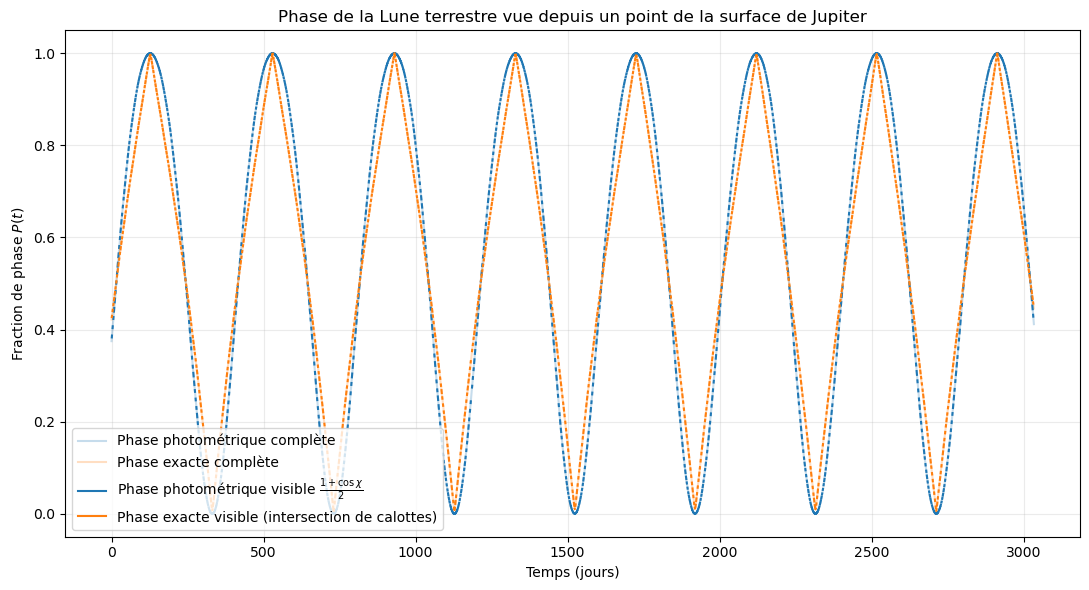

In [ ]:
# Graphique des phases lunaires (Soleil–Jupiter–Lune terrestre, point de surface Jupiter)
t_days_j = result_jupiter["t"] / 86400.0
phase_exact_j = result_jupiter["phase_visible"]
phase_photo_j = result_jupiter["phase_photometric_visible"]
phase_exact_j_full = result_jupiter["phase"]
phase_photo_j_full = result_jupiter["phase_photometric"]

fig, ax = plt.subplots(figsize=(11, 6))

# Versions complètes (sans masque visibilité) en arrière-plan
ax.plot(
    t_days_j,
    phase_photo_j_full,
    color="#1f77b4",
    alpha=0.25,
    label="Phase photométrique complète",
)
ax.plot(
    t_days_j,
    phase_exact_j_full,
    color="#ff7f0e",
    alpha=0.25,
    label="Phase exacte complète",
)

# Versions visibles (avec trous)
ax.plot(
    t_days_j,
    phase_photo_j,
    color="#1f77b4",
    label="Phase photométrique visible $\\frac{1+\\cos\\chi}{2}$",
)
ax.plot(
    t_days_j,
    phase_exact_j,
    color="#ff7f0e",
    label="Phase exacte visible (intersection de calottes)",
)

ax.set_xlabel("Temps (jours)")
ax.set_ylabel("Fraction de phase $P(t)$")
ax.set_title("Phase de la Lune terrestre vue depuis un point de la surface de Jupiter")
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

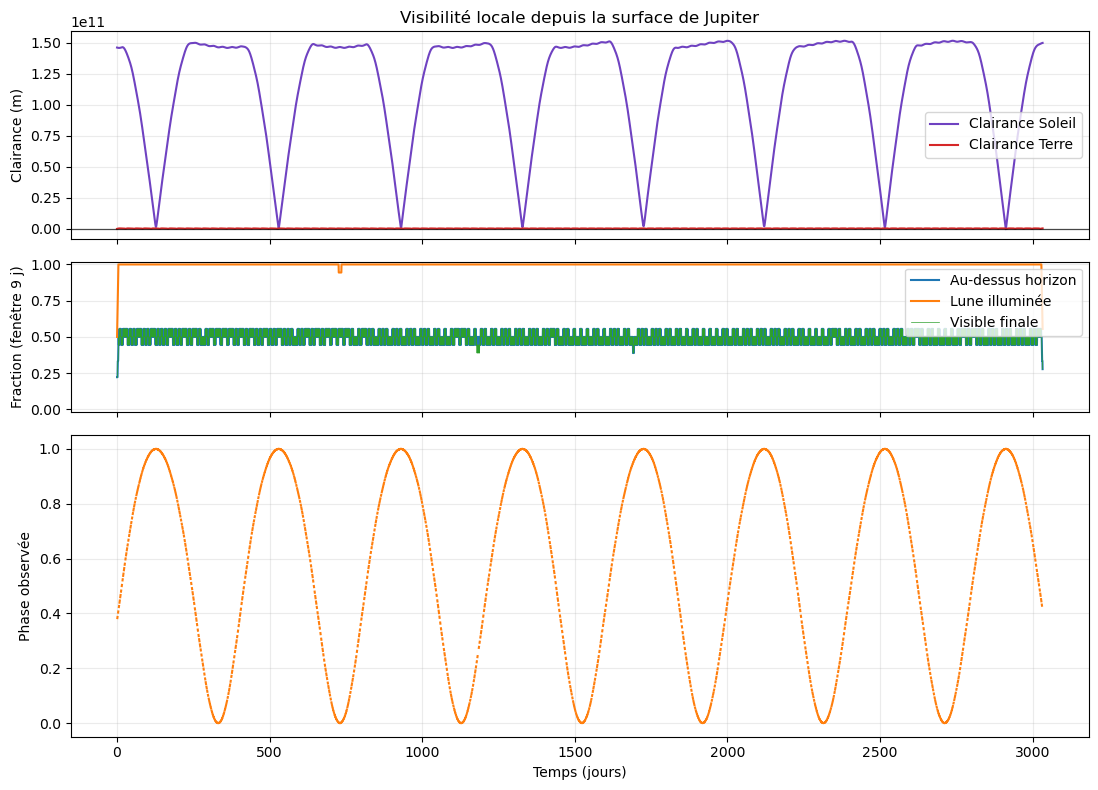

In [ ]:
# Graphiques supplémentaires: ce que voit réellement l'observateur (surface de Jupiter)
t_days_j = result_jupiter["t"] / 86400.0
visible_j = result_jupiter["visible"]
above_horizon_j = result_jupiter["above_horizon"]
illuminated_j = result_jupiter["illuminated"]
phase_obs_j = result_jupiter["phase_photometric_visible"]

# Fenêtre affichée: jusqu'à 1,5 période orbitale de Jupiter (si disponible dans la simulation)
window_days_j = 1.5 * (JUPITER_ORBIT.period_s / 86400.0)
window_mask_j = t_days_j <= (t_days_j[0] + window_days_j)

t_plot_j = t_days_j[window_mask_j]
visible_plot_j = visible_j[window_mask_j]
above_plot_j = above_horizon_j[window_mask_j]
illum_plot_j = illuminated_j[window_mask_j]
phase_obs_plot_j = phase_obs_j[window_mask_j]
clear_sun_j = result_jupiter["clear_sun"][window_mask_j]
clear_earth_j = result_jupiter["clear_earth"][window_mask_j]

visible_step_j = visible_plot_j.astype(float)
above_step_j = above_plot_j.astype(float)
illum_step_j = illum_plot_j.astype(float)

# Lissage temporel des états pour éviter l'effet "gros bloc"
if t_plot_j.size > 1:
    dt_days_j = float(np.median(np.diff(t_plot_j)))
else:
    dt_days_j = 1.0
window_state_days = 9
w = max(3, int(round(window_state_days / max(dt_days_j, 1e-9))))
kernel = np.ones(w, dtype=float) / float(w)

above_smooth = np.convolve(above_step_j, kernel, mode="same")
illum_smooth = np.convolve(illum_step_j, kernel, mode="same")
visible_smooth = np.convolve(visible_step_j, kernel, mode="same")

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [1.1, 0.8, 1.6]})

# Clairances géométriques vers la Lune
axes[0].plot(t_plot_j, clear_sun_j, color="#6f42c1", label="Clairance Soleil")
axes[0].plot(t_plot_j, clear_earth_j, color="#d62728", label="Clairance Terre")
axes[0].axhline(0.0, color="black", lw=0.9, alpha=0.7)
axes[0].set_ylabel("Clairance (m)")
axes[0].set_title("Visibilité locale depuis la surface de Jupiter")
axes[0].grid(True, alpha=0.25)
axes[0].legend()

# États lissés (fraction de temps vraie sur fenêtre glissante)
axes[1].plot(t_plot_j, above_smooth, color="#1f77b4", label="Au-dessus horizon")
axes[1].plot(t_plot_j, illum_smooth, color="#ff7f0e", label="Lune illuminée")
axes[1].plot(t_plot_j, visible_smooth, color="#2ca02c", lw=0.5, label="Visible finale")
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_ylabel(f"Fraction (fenêtre {int(window_state_days)} j)")
axes[1].grid(True, alpha=0.25)
axes[1].legend(loc="upper right")

# Phase réellement observable (trous automatiques)
axes[2].plot(t_plot_j, phase_obs_plot_j, color="#ff7f0e")
axes[2].set_ylabel("Phase observée")
axes[2].set_xlabel("Temps (jours)")
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Contrôles qualité (diagnostic) - Soleil–Jupiter–Lune terrestre (point de surface)
phase_exact_j = result_jupiter["phase"]
phase_photo_j = result_jupiter["phase_photometric"]
phase_exact_visible_j = result_jupiter["phase_visible"]
phase_photo_visible_j = result_jupiter["phase_photometric_visible"]
visible_j = result_jupiter["visible"]
above_horizon_j = result_jupiter["above_horizon"]
illuminated_j = result_jupiter["illuminated"]
blocked_sun_j = result_jupiter["blocked_sun"]
blocked_earth_j = result_jupiter["blocked_earth"]

valid_exact_j = np.isfinite(phase_exact_j)
valid_photo_j = np.isfinite(phase_photo_j)
valid_exact_visible_j = np.isfinite(phase_exact_visible_j)
valid_photo_visible_j = np.isfinite(phase_photo_visible_j)

print("--- Visibilité Jupiter(surface) -> Lune terrestre ---")
print(f"Points au-dessus horizon local : {int(above_horizon_j.sum())} / {above_horizon_j.size} ({above_horizon_j.mean():.1%})")
print(f"Points Lune illuminée          : {int(illuminated_j.sum())} / {illuminated_j.size} ({illuminated_j.mean():.1%})")
print(f"Points visibles finaux         : {int(visible_j.sum())} / {visible_j.size} ({visible_j.mean():.1%})")
print(f"Occultation par Soleil: {int(blocked_sun_j.sum())} points")
print(f"Occultation par Terre : {int(blocked_earth_j.sum())} points")

print("\n--- Qualité phase exacte (sans masque) ---")
print(f"Points valides: {int(valid_exact_j.sum())} / {phase_exact_j.size}")
if valid_exact_j.any():
    print(f"Min/Max: {np.nanmin(phase_exact_j):.6f} / {np.nanmax(phase_exact_j):.6f}")

print("\n--- Qualité phase photométrique (sans masque) ---")
print(f"Points valides: {int(valid_photo_j.sum())} / {phase_photo_j.size}")
if valid_photo_j.any():
    print(f"Min/Max: {np.nanmin(phase_photo_j):.6f} / {np.nanmax(phase_photo_j):.6f}")

print("\n--- Courbes affichées (avec masque visibilité) ---")
print(f"Exact visible: {int(valid_exact_visible_j.sum())} / {phase_exact_visible_j.size}")
print(f"Photo visible: {int(valid_photo_visible_j.sum())} / {phase_photo_visible_j.size}")

--- Visibilité Jupiter(surface) -> Lune terrestre ---
Points au-dessus horizon local : 3016 / 6067 (49.7%)
Points Lune illuminée          : 6066 / 6067 (100.0%)
Points visibles finaux         : 3015 / 6067 (49.7%)
Occultation par Soleil: 1 points
Occultation par Terre : 3 points

--- Qualité phase exacte (sans masque) ---
Points valides: 6067 / 6067
Min/Max: 0.004708 / 1.000000

--- Qualité phase photométrique (sans masque) ---
Points valides: 6067 / 6067
Min/Max: 0.000000 / 0.999997

--- Courbes affichées (avec masque visibilité) ---
Exact visible: 3015 / 6067
Photo visible: 3015 / 6067


## Données en ligne NASA / Horizons

Les cellules suivantes interrogent directement **JPL Horizons** pour récupérer les positions actuelles du Soleil, de la Terre, de la Lune et de Jupiter, puis calculer la phase actuelle de la Lune vue depuis la Terre et depuis Jupiter.

Le calcul est basé sur les vecteurs fournis par Horizons au moment de l'exécution.

Attention : dans cette version, la **phase exacte** est recalculée pour représenter la **fraction apparente du disque** de la Lune, comme la phase photométrique.
Les deux colonnes deviennent donc comparables et doivent pratiquement coïncider.

In [ ]:
from datetime import datetime, timezone
from urllib.parse import quote
from urllib.request import Request, urlopen
import json
import re
import ssl

HORIZONS_API_URL = "https://ssd.jpl.nasa.gov/api/horizons.api"
BODY_IDS = {
    "Sun": "10",
    "Earth": "399",
    "Moon": "301",
    "Jupiter": "599",
}

MONTHS_EN = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

def _utc_calendar_string(dt: datetime) -> str:
    dt = dt.astimezone(timezone.utc)
    return f"{dt.year:04d}-{MONTHS_EN[dt.month - 1]}-{dt.day:02d} {dt.hour:02d}:{dt.minute:02d}:{dt.second:02d}"


def _encode_query(params: dict[str, str]) -> str:
    return "&".join(f"{key}={quote(str(value), safe='')}" for key, value in params.items())


def _parse_horizons_vector_result(result_text: str) -> dict[str, object]:
    if "$$SOE" not in result_text or "$$EOE" not in result_text:
        raise ValueError("Réponse Horizons inattendue: bornes $$SOE / $$EOE introuvables.")

    block = result_text.split("$$SOE", 1)[1].split("$$EOE", 1)[0]
    match = re.search(
        r"X\s*=\s*([\-+0-9.Ee]+).*?Y\s*=\s*([\-+0-9.Ee]+).*?Z\s*=\s*([\-+0-9.Ee]+).*?VX\s*=\s*([\-+0-9.Ee]+).*?VY\s*=\s*([\-+0-9.Ee]+).*?VZ\s*=\s*([\-+0-9.Ee]+)",
        block,
        flags=re.S,
    )
    if match is None:
        raise ValueError("Impossible d'extraire le vecteur Horizons depuis la réponse texte.")

    x, y, z, vx, vy, vz = (float(v) for v in match.groups())
    return {
        "r": np.array([x, y, z], dtype=float) * 1_000.0,
        "v": np.array([vx, vy, vz], dtype=float) * 1_000.0,
        "raw": result_text,
    }


def _open_url_with_ssl_fallback(request: Request, timeout: float = 90.0):
    """Ouvre l'URL en essayant d'abord la vérification TLS standard, puis un repli si le certificat est intercepté localement."""
    try:
        return urlopen(request, timeout=timeout)
    except Exception as exc:
        reason = getattr(exc, "reason", exc)
        if isinstance(reason, ssl.SSLCertVerificationError):
            print("Avertissement : certificat SSL Horizons non vérifiable dans cet environnement ; repli sans vérification TLS.")
            return urlopen(request, timeout=timeout, context=ssl._create_unverified_context())
        raise


def fetch_horizons_state_vector(body_id: str, t_utc: datetime) -> dict[str, object]:
    t_str = _utc_calendar_string(t_utc)
    params = {
        "format": "json",
        "EPHEM_TYPE": "VECTORS",
        "COMMAND": f"'{body_id}'",
        "CENTER": "'500@0'",
        "MAKE_EPHEM": "'YES'",
        "TLIST": f"'{t_str}'",
        "TLIST_TYPE": "'CAL'",
        "TIME_TYPE": "'UT'",
        "OUT_UNITS": "'KM-S'",
        "REF_SYSTEM": "'ICRF'",
        "REF_PLANE": "'ECLIPTIC'",
        "VEC_TABLE": "'2'",
        "CSV_FORMAT": "'NO'",
    }
    url = f"{HORIZONS_API_URL}?{_encode_query(params)}"
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with _open_url_with_ssl_fallback(request, timeout=90) as response:
        payload = json.loads(response.read().decode("utf-8"))

    signature = payload.get("signature", {})
    if signature:
        print(f"Horizons API version: {signature.get('version', '?')} | source: {signature.get('source', '?')}")

    if "error" in payload:
        raise RuntimeError(f"Horizons a renvoyé une erreur: {payload['error']}")

    result_text = payload.get("result", "")
    if not result_text:
        raise RuntimeError("Réponse Horizons vide.")

    parsed = _parse_horizons_vector_result(result_text)
    parsed["time_utc"] = t_utc
    return parsed

In [ ]:
now_utc = datetime.now(timezone.utc).replace(microsecond=0)
print(f"Instant Horizons: {now_utc.isoformat()}")

state_vectors = {}
for name, body_id in BODY_IDS.items():
    print(f"\nRécupération Horizons pour {name} (id={body_id})...")
    state_vectors[name] = fetch_horizons_state_vector(body_id=body_id, t_utc=now_utc)

# Vecteurs barycentriques J2000/écliptiques, convertis en mètres pour rester homogènes avec le notebook.
r_sun_b = state_vectors["Sun"]["r"]
r_earth_b = state_vectors["Earth"]["r"]
r_moon_b = state_vectors["Moon"]["r"]
r_jupiter_b = state_vectors["Jupiter"]["r"]

print("\nPositions barycentriques (km, arrondies) :")
for name in ["Sun", "Earth", "Moon", "Jupiter"]:
    r_km = state_vectors[name]["r"] / 1000.0
    print(f"  {name:7s}: x={r_km[0]: .3f}  y={r_km[1]: .3f}  z={r_km[2]: .3f}")

# Passage au repère héliocentrique pour le calcul de phase.
r_earth_h = r_earth_b - r_sun_b
r_moon_h = r_moon_b - r_sun_b
r_jupiter_h = r_jupiter_b - r_sun_b

# Vecteurs utiles d'observation.
r_obs_earth = r_earth_h
r_obs_jupiter = r_jupiter_h

print("\nDistances héliocentriques (millions de km) :")
print(f"  Soleil -> Terre   : {np.linalg.norm(r_earth_h) / 1e9:.3f}")
print(f"  Soleil -> Lune    : {np.linalg.norm(r_moon_h) / 1e9:.3f}")
print(f"  Soleil -> Jupiter : {np.linalg.norm(r_jupiter_h) / 1e9:.3f}")
print(f"  Terre -> Lune     : {np.linalg.norm(r_moon_b - r_earth_b) / 1e9:.3f}")

Instant Horizons: 2026-04-14T22:53:27+00:00

Récupération Horizons pour Sun (id=10)...
Avertissement : certificat SSL Horizons non vérifiable dans cet environnement ; repli sans vérification TLS.
Horizons API version: 1.2 | source: NASA/JPL Horizons API

Récupération Horizons pour Earth (id=399)...
Avertissement : certificat SSL Horizons non vérifiable dans cet environnement ; repli sans vérification TLS.
Horizons API version: 1.2 | source: NASA/JPL Horizons API

Récupération Horizons pour Moon (id=301)...
Avertissement : certificat SSL Horizons non vérifiable dans cet environnement ; repli sans vérification TLS.
Horizons API version: 1.2 | source: NASA/JPL Horizons API

Récupération Horizons pour Jupiter (id=599)...
Avertissement : certificat SSL Horizons non vérifiable dans cet environnement ; repli sans vérification TLS.
Horizons API version: 1.2 | source: NASA/JPL Horizons API

Positions barycentriques (km, arrondies) :
  Sun    : x=-349249.074  y=-817197.889  z= 17535.566
  Earth 

Phase actuelle de la Lune à partir des données Horizons :
  (note : 'exact' et 'photométrique' visent ici la même fraction apparente du disque)
  Earth (centre)   | exact = 0.0849 | photométrique = 0.0849 | illumination ≈ 8.5%
  Jupiter (centre) | exact = 0.5704 | photométrique = 0.5704 | illumination ≈ 57.0%


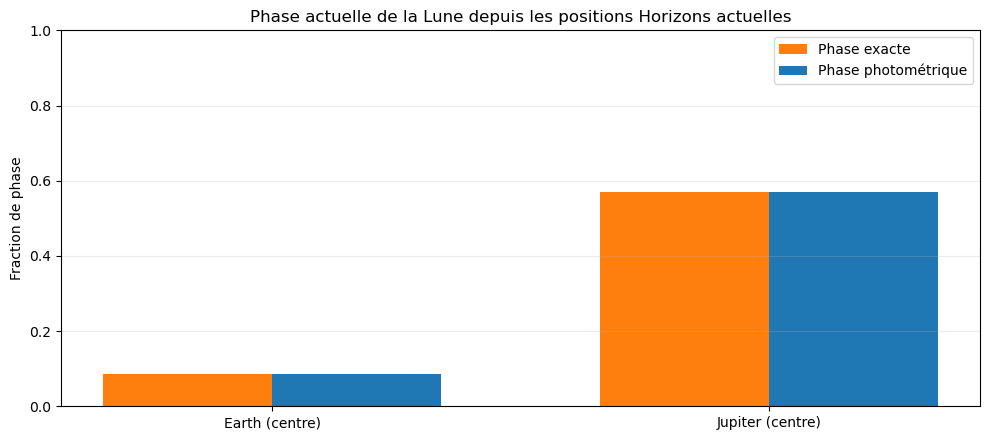

In [ ]:
earth_phase_photo = phase_fraction_photo_from_observer_point(r_obs=r_obs_earth, r_l=r_moon_h)
earth_phase_exact = earth_phase_photo

jupiter_phase_photo = phase_fraction_photo_from_observer_point(r_obs=r_obs_jupiter, r_l=r_moon_h)
jupiter_phase_exact = jupiter_phase_photo

summary = {
    "Earth (centre)": {
        "exact": earth_phase_exact,
        "photometric": earth_phase_photo,
    },
    "Jupiter (centre)": {
        "exact": jupiter_phase_exact,
        "photometric": jupiter_phase_photo,
    },
}

print("Phase actuelle de la Lune à partir des données Horizons :")
print("  (note : 'exact' et 'photométrique' visent ici la même fraction apparente du disque)")
for site, values in summary.items():
    print(
        f"  {site:16s} | exact = {values['exact']:.4f} | "
        f"photométrique = {values['photometric']:.4f} | "
        f"illumination ≈ {100.0 * values['photometric']:.1f}%"
    )

labels = list(summary.keys())
exact_vals = [summary[k]["exact"] for k in labels]
photo_vals = [summary[k]["photometric"] for k in labels]

x = np.arange(len(labels))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - width / 2, exact_vals, width, label="Phase exacte", color="#ff7f0e")
ax.bar(x + width / 2, photo_vals, width, label="Phase photométrique", color="#1f77b4")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.0, 1.0)
ax.set_ylabel("Fraction de phase")
ax.set_title("Phase actuelle de la Lune depuis les positions Horizons actuelles")
ax.grid(True, axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

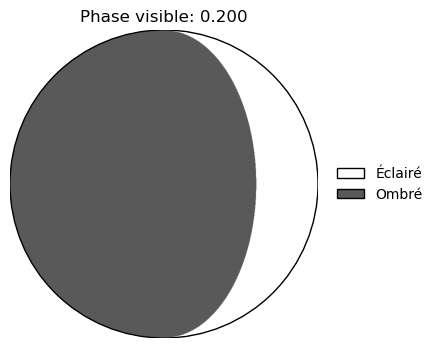

In [ ]:
f = float(np.asarray(visible).ravel()[-1])
N = 800
x = np.linspace(-1, 1, N)
y = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, y)
R2 = X**2 + Y**2
mask = R2 <= 1

# f= 0.2

if f == 0.0:
    img = np.ones((N, N, 3))
    img[mask] = 0.0
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(img, extent=[-1, 1, -1, 1], origin='lower')
    circ = plt.Circle((0, 0), 1, edgecolor='k', facecolor='none', linewidth=1)
    ax.add_patch(circ)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title("Phase visible: 0.000")
    handles = [plt.matplotlib.patches.Patch(facecolor='black', edgecolor='k', label='Nouvelle lune')]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)
    plt.show()

else:
    alpha = np.arccos(np.clip(2 * f - 1, -1, 1))
    Z = np.zeros_like(X)
    Z[mask] = np.sqrt(1 - R2[mask])
    s = np.array([np.sin(alpha), 0.0, np.cos(alpha)])
    dot = np.zeros_like(X)
    dot[mask] = s[0] * X[mask] + s[2] * Z[mask]
    lit = np.zeros_like(dot, dtype=bool)
    lit[mask] = dot[mask] > 0

    gray = 0.35
    img = np.ones((N, N, 3))
    img[mask & lit] = 1.0
    img[mask & ~lit] = gray

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(img, extent=[-1, 1, -1, 1], origin='lower')
    circ = plt.Circle((0, 0), 1, edgecolor='k', facecolor='none', linewidth=1)
    ax.add_patch(circ)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f"Phase visible: {f:.3f}")

    handles = [
        plt.matplotlib.patches.Patch(facecolor='white', edgecolor='k', label='Éclairé'),
        plt.matplotlib.patches.Patch(facecolor=str(gray), edgecolor='k', label='Ombré')
    ]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)
    plt.show()